In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from langchain_openai import ChatOpenAI
from pydantic import BaseModel, Field

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
llm = ChatOpenAI(
    model = "openai/gpt-oss-20b",
    api_key = os.getenv("GROK_API_KEY"),
    base_url = "https://api.groq.com/openai/v1",
)

In [4]:
class EvaluationSchema(BaseModel):
    feedback : str = Field(description = "Detailed feedback of the answer")
    score : int = Field(description = "Score of the feedback", ge = 0, le = 10)

In [5]:
structured_model = llm.with_structured_output(EvaluationSchema)

In [6]:
class EvaluatorState(TypedDict):
    question : str
    answer : str
    feedback : str
    score : int
    counter : int

In [7]:
def generator_answer(state : EvaluatorState) -> EvaluatorState:
    prompt = f"Explain RAG?"
    state["question"] = prompt
    answer = llm.invoke(prompt).content
    state["answer"] = answer
    state["counter"] += 1
    return {
        "answer" : answer,
        "counter" : state["counter"]
    }

In [8]:
def evaluator_answer(state : EvaluatorState) -> EvaluatorState:
    prompt = f"Evaluate the following answer {state['answer']} based on this question {state['question']}"
    response = structured_model.invoke(prompt)
    feedback = response.feedback
    score = response.score
    return {
        "feedback" : feedback,
        "score" : score
    }

In [9]:
def check_condition(state : EvaluatorState) -> Literal["Yes", "No"]:
    if (state["score"] == 10 or state["counter"] >= 2):
        return "Yes"
    else:
        return "No"


In [10]:
graph = StateGraph(EvaluatorState)
graph.add_node("generator_answer", generator_answer)
graph.add_node("evaluator_answer", evaluator_answer)

graph.add_conditional_edges(
    "evaluator_answer",
    check_condition,
    {
        "Yes": END,
        "No": "generator_answer"
    }
)

graph.add_edge(START, "generator_answer")
graph.add_edge("generator_answer", "evaluator_answer")

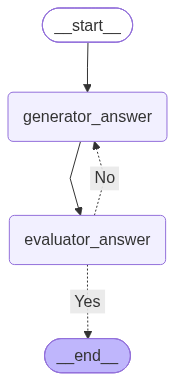

In [11]:
workflow = graph.compile()
workflow

In [12]:
initial_state = {
    "question" : "Explain RAG?",
    "counter" : 0
}
final_state = workflow.invoke(initial_state)
final_state

{'question': 'Explain RAG?',
 'answer': '## Retrieval‑Augmented Generation (RAG)\n\n**RAG** is a paradigm that blends two powerful ideas in natural language processing:\n\n| Retrieval | Generation |\n|-----------|------------|\n| Pulls in relevant external knowledge (documents, facts, web pages, etc.) | Creates fluent, context‑aware text |\n| Uses search algorithms (BM25, dense vector search, knowledge‑bases, etc.) | Uses large language models (LLMs) or sequence‑to‑sequence models |\n\nTogether, they form a **hybrid system** that can answer questions, write reports, or carry out tasks **with up‑to‑date, domain‑specific knowledge that may not be encoded in the model’s weights**.\n\n---\n\n### 1. The High‑Level Pipeline\n\n```\n          +-------------------+\n          |  User Query /     |\n          |  Input Prompt     |\n          +--------|----------+\n                   |\n           (1) Encode query into vector(s)\n                   |\n           (2) Retrieve top‑k relevant passa